In [2]:
# =============================================================================
# 1. Imports
# =============================================================================
# The notebook lives in notebooks/, so we add the project root to the path
# to import our own modules from src/.
# =============================================================================

import os
import sys

sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.stats import norm
import warnings
warnings.filterwarnings("ignore")

from src.data.loader import DataLoader
from src.risk import metrics

print("All libraries loaded successfully")

All libraries loaded successfully


In [4]:
# =============================================================================
# 2. Parameters
# =============================================================================
# Same universe as notebook 01.
#
# Why simple returns here and not log-returns?
#   1. VaR is read as "I lose X% of my capital", which is a simple return.
#   2. A portfolio return is the weighted sum of SIMPLE asset returns.
#      Log-returns add up through time, not across assets.
# Log-returns stay the right tool for time aggregation (notebook 01).
# =============================================================================

TICKERS = ["AAPL", "MSFT", "AMZN", "META", "NFLX",
           "TSLA", "NVDA", "JPM", "BAC", "XOM"]
BENCHMARK = "^GSPC"
START_DATE = "2013-01-01"
TRADING_DAYS = 252

LEVEL_95 = 5     # tail probability in % for a 95% VaR
LEVEL_99 = 1     # tail probability in % for a 99% VaR
WINDOW = 252     # rolling estimation window (1 year)

In [5]:
# =============================================================================
# 3. Data
# =============================================================================

loader = DataLoader(tickers=TICKERS, benchmark=BENCHMARK, start_date=START_DATE)
prices = loader.download()

returns = prices.pct_change(fill_method=None).dropna()
asset_returns = returns[TICKERS]
benchmark_returns = returns[BENCHMARK].rename("S&P 500")

print(f"Returns shape : {asset_returns.shape}")
print(f"From {returns.index[0].date()} to {returns.index[-1].date()}")


Returns shape : (3465, 10)
From 2013-01-03 to 2026-10-13


In [6]:
# =============================================================================
# 4. Equally weighted portfolio
# =============================================================================
# 10% in each stock, rebalanced every day back to 10%.
# This is our reference portfolio until we optimise weights in week 5.
# =============================================================================

weights = pd.Series(1 / len(TICKERS), index=TICKERS)

portfolio_returns = (asset_returns @ weights).rename("EW Portfolio")

all_returns = pd.concat(
    [asset_returns, portfolio_returns, benchmark_returns], axis=1
)

print(f"Weights : {weights.round(2).to_dict()}")
print(f"\nAnnualized vol, EW portfolio : {portfolio_returns.std() * np.sqrt(TRADING_DAYS):.2%}")
print(f"Annualized vol, S&P 500      : {benchmark_returns.std() * np.sqrt(TRADING_DAYS):.2%}")
print(f"Average single stock vol     : {(asset_returns.std() * np.sqrt(TRADING_DAYS)).mean():.2%}")

Weights : {'AAPL': 0.1, 'MSFT': 0.1, 'AMZN': 0.1, 'META': 0.1, 'NFLX': 0.1, 'TSLA': 0.1, 'NVDA': 0.1, 'JPM': 0.1, 'BAC': 0.1, 'XOM': 0.1}

Annualized vol, EW portfolio : 23.22%
Annualized vol, S&P 500      : 16.83%
Average single stock vol     : 35.42%


In [7]:
# =============================================================================
# 5. Value at Risk, 3 methods
# =============================================================================
# Historical     : empirical quantile, no distribution assumption.
# Gaussian       : mu + z * sigma, assumes Normal returns.
# Cornish-Fisher : Gaussian quantile corrected for skewness and kurtosis.
#
# Notebook 01 showed that every asset rejects normality (Jarque-Bera).
# The Gaussian VaR should therefore understate the risk, mostly at 99%,
# where fat tails matter the most.
# =============================================================================

var_table = pd.DataFrame({
    "Hist 95%": metrics.var_historic(all_returns, LEVEL_95),
    "Gauss 95%": metrics.var_gaussian(all_returns, LEVEL_95),
    "CF 95%": metrics.var_cornish_fisher(all_returns, LEVEL_95),
    "Hist 99%": metrics.var_historic(all_returns, LEVEL_99),
    "Gauss 99%": metrics.var_gaussian(all_returns, LEVEL_99),
    "CF 99%": metrics.var_cornish_fisher(all_returns, LEVEL_99),
})

print("=== 1-day VaR (% loss) ===\n")
print((var_table * 100).round(2).to_string())

# How much does the Normal assumption miss at 99%?
gap_99 = var_table["Hist 99%"] / var_table["Gauss 99%"] - 1

print("\n=== Historical vs Gaussian VaR at 99% ===")
print("(positive = the Gaussian model underestimates the real loss)\n")
print((gap_99 * 100).round(1).sort_values(ascending=False).to_string())

# Regulatory horizon: 10-day VaR with the square root of time rule
var_10d = var_table["Hist 99%"] * np.sqrt(10)
print(f"\n10-day 99% historical VaR, EW portfolio : {var_10d['EW Portfolio']:.2%}")

=== 1-day VaR (% loss) ===

              Hist 95%  Gauss 95%  CF 95%  Hist 99%  Gauss 99%  CF 99%
AAPL              2.66       2.82    2.58      4.81       4.03    6.86
MSFT              2.51       2.67    2.24      4.22       3.82    7.20
AMZN              3.01       3.27    2.78      5.53       4.67    7.22
META              3.34       3.86    2.50      5.91       5.51   16.85
NFLX              3.68       4.46    2.01      6.72       6.37   22.51
TSLA              5.14       5.73    4.96      9.00       8.19   11.05
NVDA              4.11       4.46    3.43      7.05       6.41   10.92
JPM               2.40       2.59    2.02      4.25       3.70    8.40
BAC               2.74       2.96    2.51      4.91       4.22    8.25
XOM               2.47       2.65    2.43      4.59       3.76    6.27
EW Portfolio      2.27       2.28    2.19      4.22       3.28    6.16
S&P 500           1.58       1.69    1.46      3.01       2.41    6.54

=== Historical vs Gaussian VaR at 99% ===
(posit

In [8]:
# =============================================================================
# 6. Expected Shortfall
# =============================================================================
# VaR says where the tail starts. ES says how bad it is on average once we
# are in it. ES is the measure used by FRTB (Basel) since it replaced VaR
# for market risk capital. It is also subadditive, VaR is not.
# =============================================================================

es_table = pd.DataFrame({
    "ES Hist 95%": metrics.es_historic(all_returns, LEVEL_95),
    "ES Gauss 95%": metrics.es_gaussian(all_returns, LEVEL_95),
    "ES Hist 99%": metrics.es_historic(all_returns, LEVEL_99),
    "ES Gauss 99%": metrics.es_gaussian(all_returns, LEVEL_99),
})

es_table["ES / VaR 99%"] = es_table["ES Hist 99%"] / var_table["Hist 99%"]

print("=== 1-day Expected Shortfall (% loss) ===\n")
display_es = es_table.copy()
display_es.iloc[:, :4] = display_es.iloc[:, :4] * 100
print(display_es.round(2).to_string())

# Under a Normal law, ES / VaR at 99% is about 1.15.
# A higher ratio means a thicker left tail than the Normal predicts.
normal_ratio = (norm.pdf(norm.ppf(0.01)) / 0.01) / -norm.ppf(0.01)
print(f"\nES / VaR ratio under a Normal law at 99% : {normal_ratio:.2f}")

=== 1-day Expected Shortfall (% loss) ===

              ES Hist 95%  ES Gauss 95%  ES Hist 99%  ES Gauss 99%  ES / VaR 99%
AAPL                 4.07          3.56         6.69          4.63          1.39
MSFT                 3.77          3.38         6.08          4.40          1.44
AMZN                 4.58          4.13         7.36          5.36          1.33
META                 5.24          4.87         8.97          6.34          1.52
NFLX                 5.78          5.63        10.01          7.32          1.49
TSLA                 7.79          7.23        12.47          9.41          1.39
NVDA                 6.15          5.65         9.44          7.37          1.34
JPM                  3.66          3.27         6.07          4.25          1.43
BAC                  4.16          3.73         6.87          4.84          1.40
XOM                  3.77          3.33         6.05          4.32          1.32
EW Portfolio         3.47          2.89         5.54          3.77

In [9]:
# =============================================================================
# 7. Full risk summary
# =============================================================================
# Semi-deviation only counts the bad days. Volatility penalises a +8% day
# as much as a -8% day, which is not how an investor feels risk.
# Maximum drawdown is the worst peak to trough loss over the whole period.
# =============================================================================

summary = metrics.risk_summary(all_returns, level=LEVEL_99, periods_per_year=TRADING_DAYS)
summary["Max DD date"] = metrics.max_drawdown_date(all_returns).dt.date

summary_display = summary.copy()
pct_cols = [c for c in summary.columns if c not in ("Skewness", "Excess Kurtosis", "Max DD date")]
for col in pct_cols:
    summary_display[col] = summary_display[col].map("{:.2%}".format)
summary_display["Skewness"] = summary_display["Skewness"].round(2)
summary_display["Excess Kurtosis"] = summary_display["Excess Kurtosis"].round(2)

print("=== Risk Summary (daily data, 99% level) ===\n")
print(summary_display.to_string())

=== Risk Summary (daily data, 99% level) ===

             Volatility (ann.) Semi-deviation (ann.)  Skewness  Excess Kurtosis VaR Hist 99% VaR Gauss 99% VaR CF 99% ES Hist 99% Max Drawdown Max DD date
AAPL                    28.20%                19.30%     -0.01             6.81        4.81%         4.03%      6.86%       6.69%       38.52%  2019-01-03
MSFT                    26.82%                17.94%      0.24             9.39        4.22%         3.82%      7.20%       6.08%       37.15%  2022-11-03
AMZN                    32.58%                21.76%      0.36             6.66        5.53%         4.67%      7.22%       7.36%       56.15%  2022-12-28
META                    38.48%                25.67%      0.42            21.63        5.91%         5.51%     16.85%       8.97%       76.74%  2022-11-03
NFLX                    44.52%                28.59%      0.95            29.04        6.72%         6.37%     22.51%      10.01%       75.95%  2022-05-11
TSLA                    

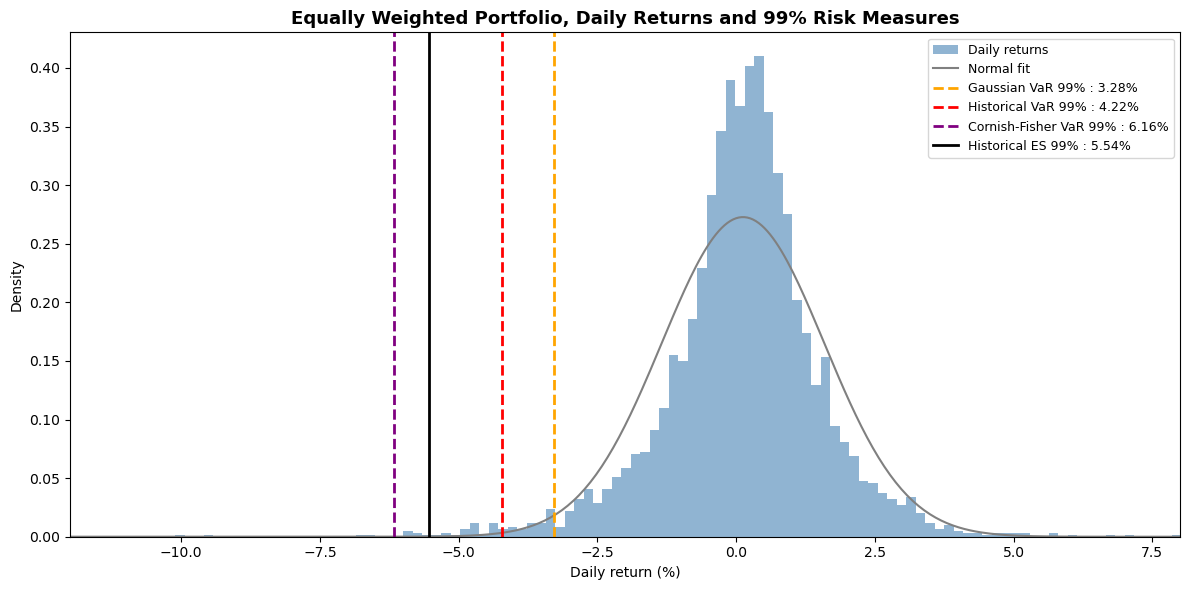

Figure saved : 07_var_distribution


In [10]:
# =============================================================================
# 8. Figure 07, portfolio return distribution and risk thresholds
# =============================================================================

port = portfolio_returns * 100
v_hist = var_table.loc["EW Portfolio", "Hist 99%"] * 100
v_gauss = var_table.loc["EW Portfolio", "Gauss 99%"] * 100
v_cf = var_table.loc["EW Portfolio", "CF 99%"] * 100
es_99 = es_table.loc["EW Portfolio", "ES Hist 99%"] * 100

fig7, ax = plt.subplots(figsize=(12, 6))

ax.hist(port, bins=150, density=True, color="steelblue", alpha=0.6, label="Daily returns")

x = np.linspace(port.min(), port.max(), 500)
ax.plot(x, norm.pdf(x, port.mean(), port.std()), color="grey", linewidth=1.5,
        label="Normal fit")

ax.axvline(-v_gauss, color="orange", linestyle="--", linewidth=2,
           label=f"Gaussian VaR 99% : {v_gauss:.2f}%")
ax.axvline(-v_hist, color="red", linestyle="--", linewidth=2,
           label=f"Historical VaR 99% : {v_hist:.2f}%")
ax.axvline(-v_cf, color="purple", linestyle="--", linewidth=2,
           label=f"Cornish-Fisher VaR 99% : {v_cf:.2f}%")
ax.axvline(-es_99, color="black", linestyle="-", linewidth=2,
           label=f"Historical ES 99% : {es_99:.2f}%")

ax.set_xlim(-12, 8)
ax.set_title("Equally Weighted Portfolio, Daily Returns and 99% Risk Measures",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Daily return (%)")
ax.set_ylabel("Density")
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("../figures/07_var_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved : 07_var_distribution")

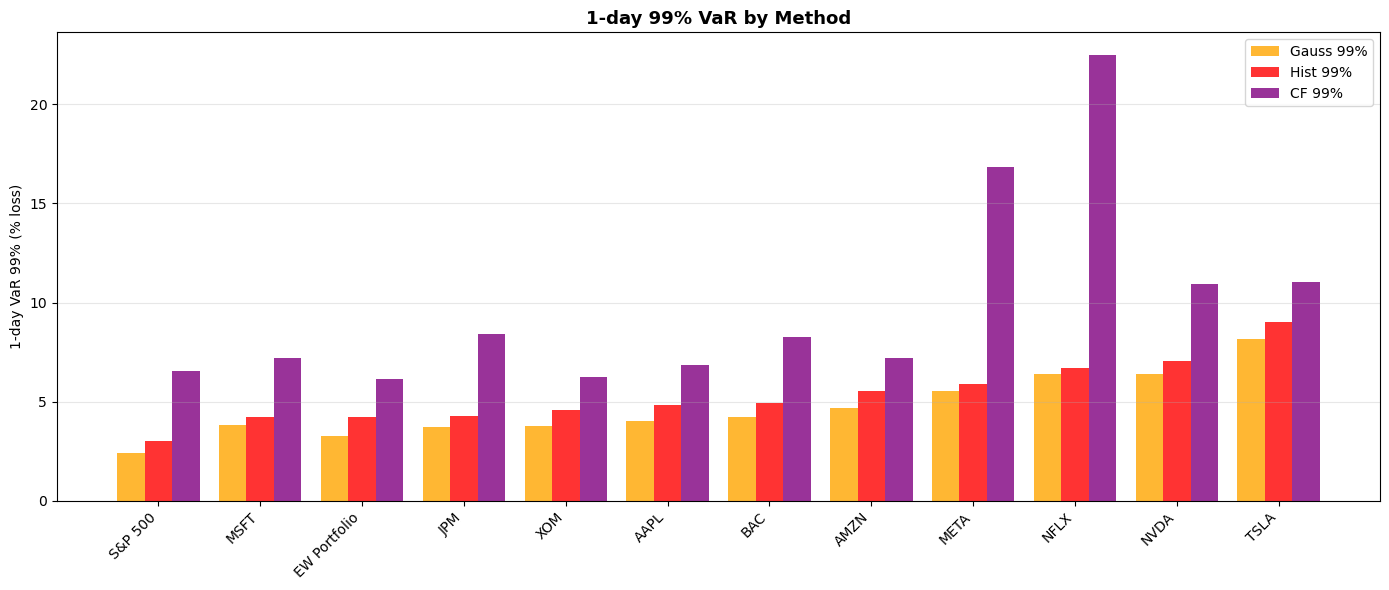

Figure saved : 08_var_by_method


In [11]:
# =============================================================================
# 9. Figure 08, VaR 99% by method and by asset
# =============================================================================

var_99 = var_table[["Gauss 99%", "Hist 99%", "CF 99%"]] * 100
var_99 = var_99.sort_values("Hist 99%")

positions = np.arange(len(var_99))
bar_width = 0.27
colors = ["orange", "red", "purple"]

fig8, ax = plt.subplots(figsize=(14, 6))

for i, (col, color) in enumerate(zip(var_99.columns, colors)):
    ax.bar(positions + (i - 1) * bar_width, var_99[col], width=bar_width,
           color=color, alpha=0.8, label=col)

ax.set_xticks(positions)
ax.set_xticklabels(var_99.index, rotation=45, ha="right")
ax.set_ylabel("1-day VaR 99% (% loss)")
ax.set_title("1-day 99% VaR by Method", fontsize=13, fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../figures/08_var_by_method.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved : 08_var_by_method")


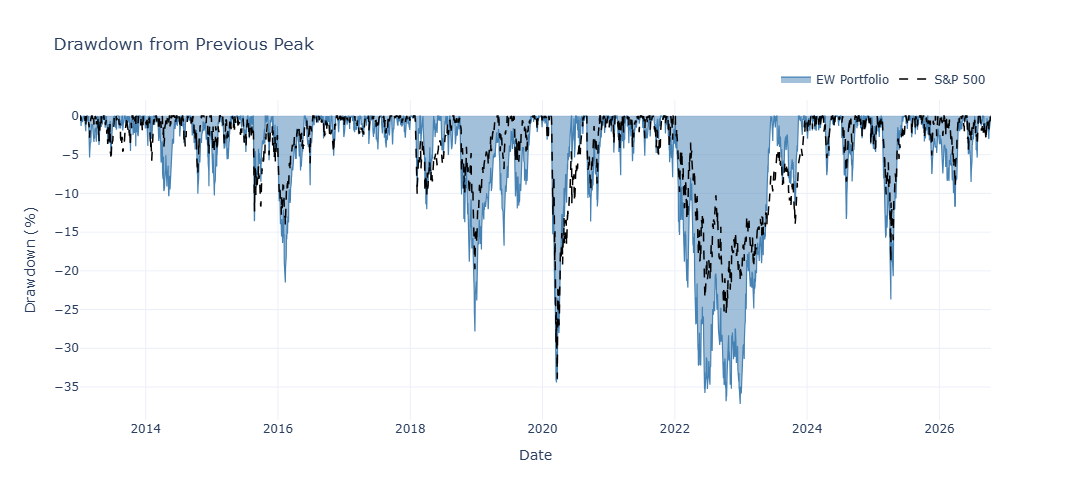

Figure saved : 09_drawdown


In [12]:
# =============================================================================
# 10. Figure 09, drawdowns (underwater chart)
# =============================================================================
# 0% = new all time high. The deeper the curve, the bigger the loss
# from the last peak. The width of each trough is the time to recover.
# =============================================================================

dd = metrics.drawdown(all_returns[["EW Portfolio", "S&P 500"]]) * 100

fig9 = go.Figure()

fig9.add_trace(go.Scatter(
    x=dd.index, y=dd["EW Portfolio"], name="EW Portfolio",
    mode="lines", fill="tozeroy", line=dict(width=1.2, color="steelblue")
))
fig9.add_trace(go.Scatter(
    x=dd.index, y=dd["S&P 500"], name="S&P 500",
    mode="lines", line=dict(width=1.5, color="black", dash="dash")
))

fig9.update_layout(
    title="Drawdown from Previous Peak",
    xaxis_title="Date",
    yaxis_title="Drawdown (%)",
    template="plotly_white",
    height=500,
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)

fig9.show()
fig9.write_html("../figures/09_drawdown.html", include_plotlyjs="cdn")
print("Figure saved : 09_drawdown")


In [13]:
# =============================================================================
# 11. Rolling VaR backtest
# =============================================================================
# A VaR number is useless if it is wrong. We test each method out of sample:
#   - each day, VaR is estimated on the previous 252 days only
#   - an exception = a day where the real loss is larger than the VaR
#   - at 99%, we expect about 1 exception every 100 days
#
# Kupiec test (1995): is the observed exception rate statistically
# different from 1%? p-value < 0.05 means the model is rejected.
#
# Basel traffic light on the last 250 days:
# Green 0 to 4 exceptions, Yellow 5 to 9, Red 10 or more.
# =============================================================================

methods = ["historic", "gaussian", "cornish-fisher"]

rolling_vars = pd.DataFrame({
    m: metrics.rolling_var(portfolio_returns, window=WINDOW, level=LEVEL_99, method=m)
    for m in methods
})

backtest = pd.DataFrame({
    m: metrics.kupiec_test(portfolio_returns, rolling_vars[m], level=LEVEL_99)
    for m in methods
}).T

last_250 = portfolio_returns.iloc[-250:]
var_last_250 = rolling_vars.iloc[-250:]

# exception when return + VaR < 0, i.e. the loss is bigger than the VaR
exceptions_250 = (var_last_250.add(last_250, axis=0) < 0).sum()

backtest["Exceptions (last 250d)"] = exceptions_250
backtest["Basel zone"] = exceptions_250.map(metrics.basel_zone)
backtest["Reject at 5%"] = backtest["p-value"].astype(float) < 0.05

backtest_display = backtest.copy()
backtest_display[["Observations", "Exceptions"]] = backtest_display[["Observations", "Exceptions"]].astype(int)
backtest_display["Exception rate"] = backtest_display["Exception rate"].astype(float).map("{:.2%}".format)
backtest_display["LR stat"] = backtest_display["LR stat"].astype(float).round(2)
backtest_display["p-value"] = backtest_display["p-value"].astype(float).round(4)

print("=== 99% VaR Backtest, EW Portfolio ===\n")
print(backtest_display.to_string())

=== 99% VaR Backtest, EW Portfolio ===

                Observations  Exceptions  Expected Exception rate  LR stat  p-value  Exceptions (last 250d) Basel zone  Reject at 5%
historic                3213          46      32.1          1.43%     5.33   0.0209                       0      Green          True
gaussian                3213          87      32.1          2.71%    64.54   0.0000                       2      Green          True
cornish-fisher          3213          42      32.1          1.31%     2.79   0.0947                       1      Green         False


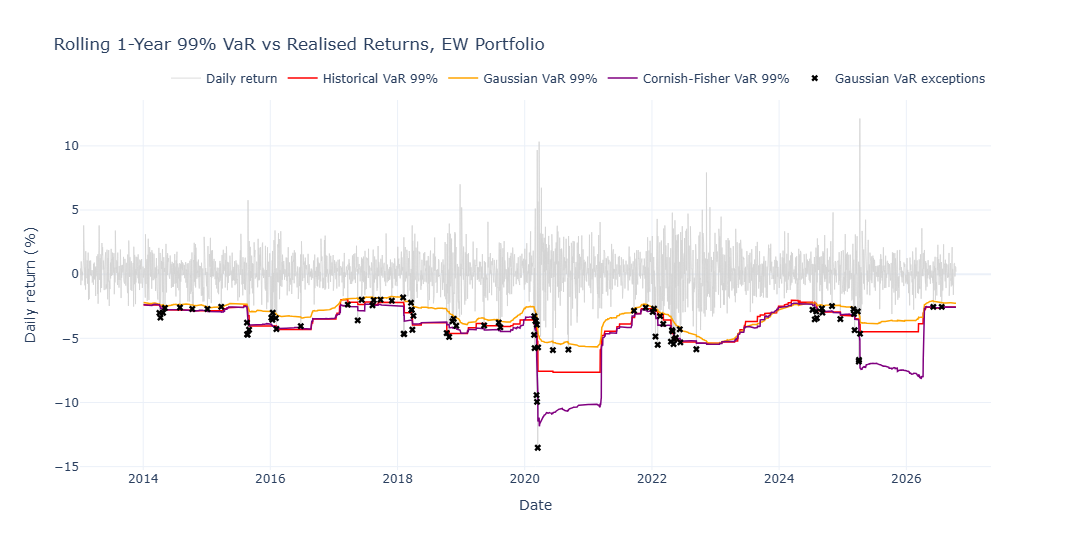

Figure saved : 10_var_backtest


In [14]:
# =============================================================================
# 12. Figure 10, rolling VaR vs realised returns
# =============================================================================

port_pct = portfolio_returns * 100
rv_pct = rolling_vars * 100

gauss_exceptions = port_pct[port_pct < -rv_pct["gaussian"]]

fig10 = go.Figure()

fig10.add_trace(go.Scatter(
    x=port_pct.index, y=port_pct, name="Daily return",
    mode="lines", line=dict(width=0.8, color="lightgrey")
))

line_styles = {
    "historic": ("Historical VaR 99%", "red"),
    "gaussian": ("Gaussian VaR 99%", "orange"),
    "cornish-fisher": ("Cornish-Fisher VaR 99%", "purple"),
}

for m, (label, color) in line_styles.items():
    fig10.add_trace(go.Scatter(
        x=rv_pct.index, y=-rv_pct[m], name=label,
        mode="lines", line=dict(width=1.5, color=color)
    ))

fig10.add_trace(go.Scatter(
    x=gauss_exceptions.index, y=gauss_exceptions, name="Gaussian VaR exceptions",
    mode="markers", marker=dict(size=6, color="black", symbol="x")
))

fig10.update_layout(
    title="Rolling 1-Year 99% VaR vs Realised Returns, EW Portfolio",
    xaxis_title="Date",
    yaxis_title="Daily return (%)",
    template="plotly_white",
    height=550,
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)

fig10.show()
fig10.write_html("../figures/10_var_backtest.html", include_plotlyjs="cdn")
print("Figure saved : 10_var_backtest")



## Conclusions

**1. Diversification works, but this portfolio is still riskier than the index**

The equally weighted portfolio has an annualized volatility of 23.2%, against 35.4%
on average for a single stock: holding the ten names together removes about a third
of the risk. It remains well above the S&P 500 (16.8%), because equal weighting gives
30% of the capital to the three most volatile stocks (TSLA 57%, NVDA 45%, NFLX 45%).
Semi-deviation is about 70% of volatility for the portfolio, so most of the measured
risk is not symmetric noise but real downside.

**2. The Normal assumption is wrong in both directions**

At 95%, the Gaussian VaR is slightly higher than the historical VaR for all 12 series.
At 99%, it is lower for all 12. This is the typical shape of fat-tailed returns: more
mass around zero and in the extreme tails than a Normal law allows, less in between.
The largest 99% gaps are not on single stocks but on the diversified series: the
Gaussian VaR misses the historical one by 28.7% for the portfolio and 24.7% for the
S&P 500. Diversification lowers volatility, but in a crash the stocks fall together,
and the Normal model has no way to capture that.

**3. Cornish-Fisher overcorrects when kurtosis is extreme**

The Cornish-Fisher VaR at 99% is above the historical VaR for every series, and far
above it for the stocks with the highest excess kurtosis: 22.5% vs 6.7% for NFLX
(kurtosis 29), 16.9% vs 5.9% for META (kurtosis 22). For these two names it is even
above the historical Expected Shortfall. Their kurtosis is driven by a handful of
single-day collapses (earnings in 2022), and the expansion is only reliable for
moderate departures from normality. Cornish-Fisher is a correction, not a model of
the tail, and it should be used with that limit in mind.

**4. The tail is deeper than a Normal law predicts**

For the portfolio, the 99% Expected Shortfall is 5.5%, i.e. 1.31 times the 99% VaR.
Across all series the ratio ranges from 1.31 to 1.52, against 1.15 under a Normal
law. Once the VaR threshold is crossed, losses are significantly deeper than a
Gaussian model expects, which is the reason the Basel FRTB framework replaced VaR
with Expected Shortfall.

**5. Drawdowns: two different crises**

The worst drawdown of the portfolio is 37.2%, reached on 28 December 2022, at the end
of the Fed tightening cycle that hit growth stocks hardest. The S&P 500's worst
drawdown is 33.9%, reached on 23 March 2020 during the Covid crash. The banks and XOM
also bottomed in March 2020, while META (-77%), NFLX (-76%) and TSLA (-74%) had their
worst losses in 2022. The portfolio's risk profile is driven by its tech exposure,
not by the broad market.

**6. VaR backtest: only Cornish-Fisher passes**

Each method was re-estimated every day on the previous 252 days and tested on the
next day, over 3,213 out-of-sample days. A correct 99% VaR should be breached about
32 times.

| Method | Exceptions | Exception rate | Kupiec p-value | Result |
|---|---|---|---|---|
| Historical | 46 | 1.43% | 0.021 | Rejected |
| Gaussian | 87 | 2.71% | 0.000 | Rejected |
| Cornish-Fisher | 42 | 1.31% | 0.095 | Not rejected |

The Gaussian VaR is breached almost three times more often than it should be. The
historical VaR is closer but still rejected. Cornish-Fisher is the only method whose
exception rate is statistically consistent with 1%. This nuances point 3: on rolling
one-year windows, kurtosis is rarely as extreme as on the full sample, and the
correction does its job. Its cost shows on figure 10: after a shock it becomes very
conservative (close to -12% after March 2020, around -8% in 2025-2026), which would
mean holding a lot of capital against losses that do not come.

All three methods are in the Basel green zone on the last 250 days, but that year
was calm. The full-sample test is the more informative one.

Two structural limits are visible on figure 10. First, exceptions are not spread
evenly: they cluster in August 2015, early 2018, March 2020, 2022 and April 2025.
Kupiec only tests how many exceptions occur, not when; the Christoffersen test would
check their independence. Second, the historical VaR moves in steps: the Covid crash
stays in the window for exactly one year and then disappears overnight in March 2021.
Both problems come from treating every past day with the same weight, which is what
a GARCH model or an exponentially weighted volatility would fix.